# Trình diễn OLAP trên kho dữ liệu chất lượng không khí Bắc Kinh

**Kho:** PostgreSQL, lược đồ hình sao `dwh.fact_air_quality_hourly` (độ mịn: 1 trạm × 1 giờ, 420 768 dòng).

| Chiều | Phân cấp khái niệm | Số mức |
|---|---|---|
| Thời gian (`dim_date`) | ngày → tháng → quý → năm (song song: mùa) | 4 |
| Giờ trong ngày (`dim_time`) | giờ → buổi | 2 |
| Địa điểm (`dim_station`) | trạm → quận | 2 |
| Hướng gió (`dim_wind_direction`) | hướng (16) → phần tư (4) → chế độ gió (2) | 3 |

Số khối con của khối 4 chiều có phân cấp: **T = (4+1)(2+1)(2+1)(3+1) = 180**.

| Thao tác | Ý nghĩa |
|---|---|
| Roll-up (cuộn lên) | đi lên một mức trong phân cấp, hoặc bỏ bớt một chiều |
| Drill-down (khoan xuống) | đi xuống mức chi tiết hơn, hoặc thêm một chiều |
| Slice (cắt lát) | cố định một giá trị trên một chiều → khối con ít chiều hơn |
| Dice (cắt khối) | chọn khoảng giá trị trên nhiều chiều → khối con nhỏ hơn |
| Pivot (xoay trục) | đổi chiều trên hàng / cột — cùng dữ liệu, khung nhìn khác |

Toàn bộ câu SQL nằm trong `sql/olap/olap_operations.sql`.


In [1]:
from pathlib import Path
import sys, json, time
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
try:
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env")
except ImportError:
    pass

import matplotlib.pyplot as plt
import pandas as pd
from src.olap.queries import load_queries, run_query

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
Q = load_queries()

def show(name):
    q = Q[name]
    print(f"[{q.op}] {q.desc}")
    return run_query(name, Q)


## 1. Roll-up — cuộn lên trên chiều Thời gian (ngày → tháng → năm)


[ROLL-UP (mức chi tiết: ngày)] Trạm Dongsi, tháng 12/2015 — PM2.5 trung bình theo NGÀY (điểm xuất phát).
[ROLL-UP (ngày → tháng)] Cuộn lên một mức trên chiều Thời gian: cùng trạm Dongsi, gộp theo THÁNG của năm 2015.
[ROLL-UP (tháng → năm)] Cuộn lên tiếp đến mức NĂM (toàn bộ giai đoạn) cho trạm Dongsi.


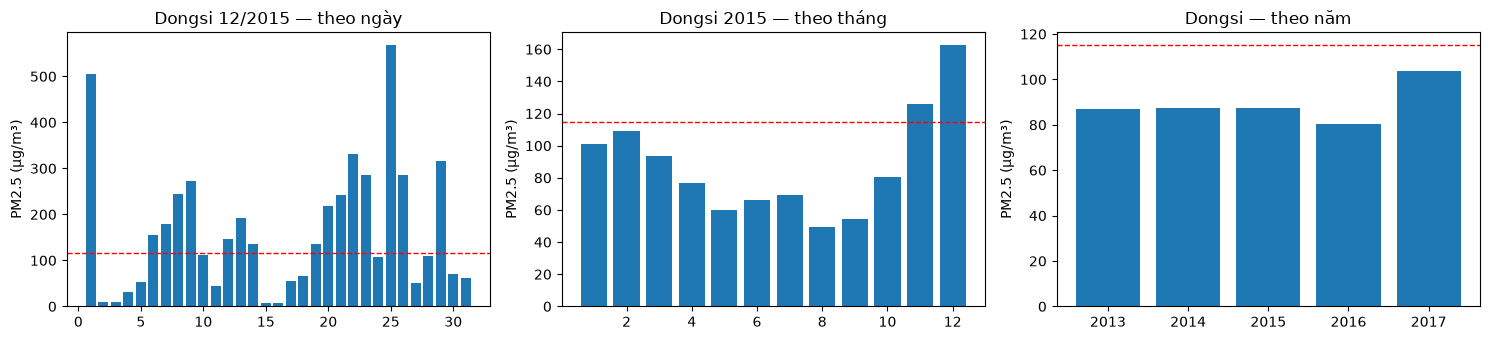

,year,pm25_avg,hours
0,2013,86.9,7344
1,2014,87.5,8760
2,2015,87.3,8760
3,2016,80.2,8784
4,2017,103.5,1416


In [2]:
day = show('rollup_day'); month = show('rollup_month'); year = show('rollup_year')
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].bar(pd.to_datetime(day['date_day']).dt.day, day['pm25_avg']); axes[0].set_title('Dongsi 12/2015 — theo ngày')
axes[1].bar(month['month'], month['pm25_avg']); axes[1].set_title('Dongsi 2015 — theo tháng')
axes[2].bar(year['year'].astype(str), year['pm25_avg']); axes[2].set_title('Dongsi — theo năm')
for ax in axes: ax.axhline(115, color='red', ls='--', lw=1); ax.set_ylabel('PM2.5 (µg/m³)')
plt.tight_layout(); plt.show()
year


Ngày 01/12/2015 trung bình **>500 µg/m³** (đợt khói mù lịch sử ở Bắc Kinh). Khi cuộn lên mức tháng/năm, đỉnh này bị "pha loãng". Đó là lý do phải giữ độ mịn giờ trong bảng sự kiện. Lưu ý: năm 2017 chỉ có tháng 1–2 (mùa đông) nên trung bình cao hơn.


In [3]:
show('rollup_station_to_district')


[ROLL-UP (trạm → quận)] Cuộn lên trên chiều Địa điểm: 12 trạm gộp thành 8 quận (năm 2016).


,district,stations,pm25_avg,hours
0,Xicheng,2,77.8,17568
1,Shijingshan,1,77.4,8784
2,Dongcheng,2,77.0,17568
3,Chaoyang,2,75.1,17568
4,Shunyi,1,71.8,8784
5,Haidian,1,71.4,8784
6,Huairou,1,61.1,8784
7,Changping,2,60.8,17568


In [4]:
show('rollup_operator')  # dòng NULL = tổng con của mức cha; grouping_id cho biết mức nào bị gộp


[ROLL-UP (toán tử ROLLUP)] GROUP BY ROLLUP(year, quarter, month) — tổng con mọi mức của phân cấp Thời gian trong một câu; dòng NULL là mức "ALL".


,year,quarter,month,grouping_id,pm25_avg,hours
0,2016.0,1.0,1.0,0,66.9,8928
1,2016.0,1.0,2.0,0,42.8,8352
2,2016.0,1.0,3.0,0,92.0,8928
3,2016.0,1.0,NaN,1,67.7,26208
4,2016.0,2.0,4.0,0,67.0,8640
5,2016.0,2.0,5.0,0,53.7,8928
6,2016.0,2.0,6.0,0,58.5,8640
7,2016.0,2.0,NaN,1,59.6,26208
8,2016.0,3.0,7.0,0,68.1,8928
9,2016.0,3.0,8.0,0,45.8,8928


## 2. Drill-down — khoan xuống: năm → quý → tháng → buổi trong ngày


[DRILL-DOWN (mức năm)] Bắt đầu ở mức tổng hợp: PM2.5 trung bình toàn mạng lưới theo NĂM.
[DRILL-DOWN (năm → quý)] Khoan xuống năm 2015 theo QUÝ — quý 4 nổi bật.


[DRILL-DOWN (quý → tháng)] Khoan xuống quý 4/2015 theo THÁNG.


[DRILL-DOWN (tháng → buổi trong ngày, chiều Giờ)] Khoan xuống tháng 12/2015 theo chiều thứ hai: BUỔI trong ngày (dim_time).


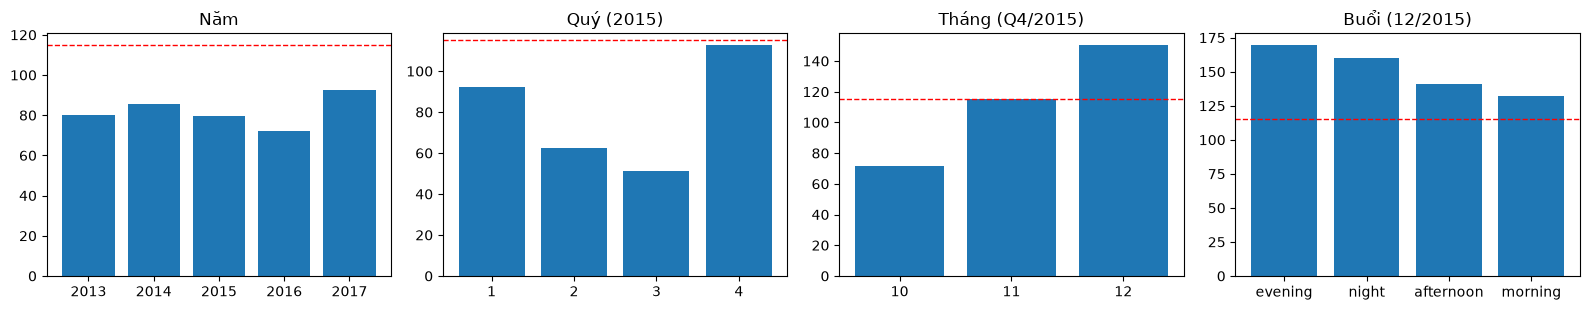

,month,pm25_avg,exceed_hours
0,10,71.8,1592
1,11,115.5,3230
2,12,150.5,4343


In [5]:
levels = [show('drilldown_year'), show('drilldown_quarter'), show('drilldown_month'), show('drilldown_daypart')]
keys = ['year', 'quarter', 'month', 'day_part']
titles = ['Năm', 'Quý (2015)', 'Tháng (Q4/2015)', 'Buổi (12/2015)']
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, df, k, t in zip(axes, levels, keys, titles):
    ax.bar(df[k].astype(str), df['pm25_avg']); ax.set_title(t); ax.axhline(115, color='red', ls='--', lw=1)
plt.tight_layout(); plt.show()
levels[2]


Khoan xuống cho thấy quý 4/2015 là đỉnh, tháng 12 xấu nhất (150 µg/m³), và buổi tối/đêm cao hơn buổi sáng. Đây là gợi ý trực tiếp cho thời điểm phát cảnh báo.


## 3. Slice — cắt lát tại quận = 'Dongcheng'


In [6]:
s = show('slice_district')
s.pivot(index='year', columns='season', values='pm25_avg')[['spring', 'summer', 'autumn', 'winter']]


[SLICE] Cắt lát chiều Địa điểm tại quận = 'Dongcheng' → khối con 2 chiều (năm × mùa).


season,spring,summer,autumn,winter
year,,,,
2013,85.5,81.5,88.0,85.4
2014,83.3,74.4,89.8,101.6
2015,74.2,60.0,84.0,122.3
2016,74.1,61.8,83.7,88.1
2017,NaN,NaN,NaN,100.9


## 4. Dice — mùa ∈ {thu, đông} × gió nam/bắc × quận ∈ {Dongcheng, Xicheng}


In [7]:
dice = pd.concat([show('dice_winter_south_core'), show('dice_compare_north')])
dice.pivot_table(index=['district', 'season'], columns='wind_regime', values=['pm25_avg', 'pct_exceed'])


[DICE] Khối con theo 3 chiều: mùa ∈ {đông, thu} × chế độ gió = nam × quận ∈ {Dongcheng, Xicheng}.
[DICE (đối chứng)] Cùng khối con nhưng chế độ gió = bắc — để thấy gió nam làm PM2.5 tăng gấp nhiều lần.


pct_exceed            pm25_avg          
wind_regime       northerly southerly northerly southerly
district  season                                         
Dongcheng autumn       24.4      32.0      77.5      96.8
          winter       27.8      43.5      83.8     133.0
Xicheng   autumn       25.4      30.3      81.0      95.0
          winter       29.5      42.6      87.7     132.4

Với cùng quận và cùng mùa, **gió nam** (khí từ đồng bằng Hà Bắc) làm PM2.5 mùa đông tăng từ ~85 lên ~133 µg/m³, và tỷ lệ giờ vượt ngưỡng 115 tăng từ ~28% lên ~43%. Đây là lý do chiều Hướng gió được đưa vào kho.


## 5. Pivot — xoay trục: trạm × tháng ⇄ tháng × trạm


[PIVOT (xoay trục)] Xoay trục: trạm trên hàng, tháng (năm 2016) lên cột — bảng chéo bằng FILTER.


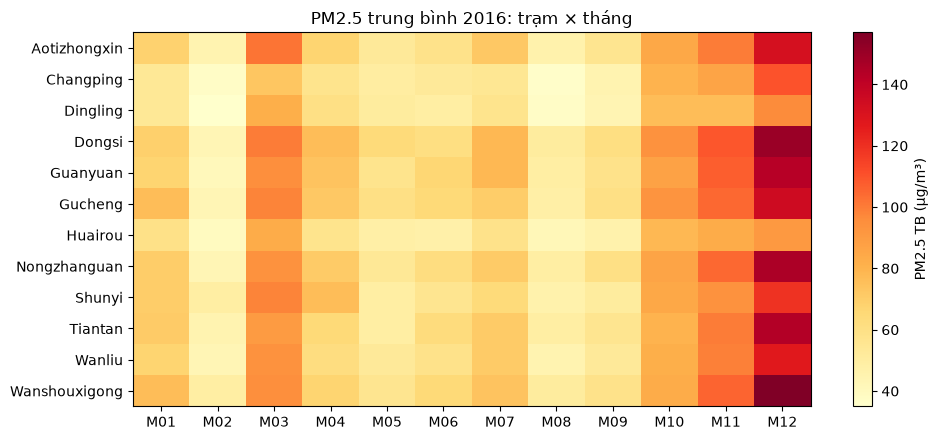

station_name,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
m01,68.0,54.0,54.0,69.0,67.0,76.0,59.0,70.0,70.0,71.0,67.0,76.0
m02,45.0,37.0,35.0,43.0,41.0,43.0,39.0,43.0,49.0,45.0,43.0,49.0
m03,102.0,73.0,82.0,100.0,95.0,98.0,83.0,94.0,98.0,90.0,94.0,95.0
m04,67.0,57.0,60.0,76.0,74.0,72.0,57.0,71.0,76.0,65.0,62.0,67.0
m05,53.0,50.0,51.0,64.0,57.0,60.0,48.0,54.0,49.0,49.0,53.0,56.0


In [8]:
p = show('pivot_station_month').set_index('station_name')
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(p.values.astype(float), cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(12), [c.upper() for c in p.columns]); ax.set_yticks(range(len(p)), p.index)
fig.colorbar(im, label='PM2.5 TB (µg/m³)'); ax.set_title('PM2.5 trung bình 2016: trạm × tháng')
plt.tight_layout(); plt.show()
p.T.head()  # xoay trục: tháng trên hàng, trạm trên cột


In [9]:
show('pivot_season_wind')  # đọc từ khối tính trước mart_olap_cube


[PIVOT (xoay trục)] Cùng dữ liệu, khung nhìn khác: mùa trên hàng × phần tư hướng gió trên cột (đọc từ khối đã tính trước).


,season,gio_dong_bac,gio_dong_nam,gio_tay_nam,gio_tay_bac
0,spring,76.1,94.2,81.2,54.8
1,summer,58.2,79.0,69.5,47.9
2,autumn,86.3,100.8,81.4,60.6
3,winter,101.9,136.9,106.0,61.5


## 6. CUBE, GROUPING SETS và trả lời truy vấn từ khối đã tính trước


In [10]:
show('cube_operator')


[CUBE] GROUP BY CUBE(season, wind_regime) — mọi tổ hợp 2 chiều + tổng con + tổng toàn bộ (2² = 4 khối con).


,season,wind_regime,grouping_id,pm25_avg,hours
0,autumn,northerly,0,76.1,63260
1,autumn,southerly,0,91.9,41572
2,spring,northerly,0,66.3,51924
3,spring,southerly,0,87.2,54060
4,summer,northerly,0,54.5,51674
5,summer,southerly,0,74.3,54310
6,winter,northerly,0,83.2,70814
7,winter,southerly,0,121.8,33154
8,autumn,ALL,1,82.3,104832
9,spring,ALL,1,77.0,105984


In [11]:
show('grouping_sets')


[GROUPING SETS] Chỉ tính đúng 3 khối con cần cho báo cáo: theo quận, theo buổi, và tổng.


,district,day_part,pm25_avg,hours
0,ALL,ALL,79.8,420768
1,ALL,afternoon,75.4,105192
2,ALL,evening,85.6,105192
3,ALL,morning,75.4,105192
4,ALL,night,82.7,105192
5,Changping,ALL,68.5,70128
6,Chaoyang,ALL,83.8,70128
7,Dongcheng,ALL,84.2,70128
8,Haidian,ALL,83.4,35064
9,Huairou,ALL,69.6,35064


In [12]:
from src.eda.db import read_sql
t0 = time.perf_counter()
scan = read_sql("select calendar.year, calendar.season, avg(f.pm25_ug_m3) as pm25_avg "
                "from dwh.fact_air_quality_hourly f join dwh.dim_date calendar on f.date_key = calendar.date_key "
                "group by 1, 2")
t_fact = time.perf_counter() - t0
t0 = time.perf_counter(); cube = show('cube_lookup'); t_cube = time.perf_counter() - t0
print(f'Quét fact (420 768 dòng): {t_fact*1000:.0f} ms | đọc khối con (17 ô): {t_cube*1000:.0f} ms')
cube.head(8)


[Trả lời từ khối đã tính trước] Đọc thẳng khối con (year, season) trong mart_olap_cube thay vì quét 420 768 dòng fact.
Quét fact (420 768 dòng): 174 ms | đọc khối con (17 ô): 38 ms


,year,season,pm25_avg,hour_count
0,2013,spring,83.2,26496
1,2013,summer,76.7,26496
2,2013,autumn,80.8,26208
3,2013,winter,78.5,8928
4,2014,spring,82.5,26496
5,2014,summer,69.4,26496
6,2014,autumn,90.9,26208
7,2014,winter,100.2,25920


In [13]:
show('cuboid_inventory')


[Danh mục khối con] 32 khối con trong mart_olap_cube và số ô của từng khối.


,grouping_id,cuboid,cells,hours
0,0,"year,season,district,day_part,wind_quadrant",2176,420768.0
1,1,"year,season,district,day_part",544,420768.0
2,2,"year,season,district,wind_quadrant",544,420768.0
3,3,"year,season,district",136,420768.0
4,4,"year,season,day_part,wind_quadrant",272,420768.0
5,5,"year,season,day_part",68,420768.0
6,6,"year,season,wind_quadrant",68,420768.0
7,7,"year,season",17,420768.0
8,8,"year,district,day_part,wind_quadrant",640,420768.0
9,9,"year,district,day_part",160,420768.0


## 7. Kiểm chứng tính đúng của các khối đã tính trước


In [14]:
checks = json.loads((ROOT / 'artifacts' / 'dwh' / 'olap_checks.json').read_text(encoding='utf-8'))
print(checks['summary'])
pd.DataFrame(checks['cuboid_checks'])[['cuboid', 'cells', 'matched', 'pct_correct']]


{'cuboids_checked': 35, 'cuboids_fully_correct': 35, 'cells_checked': 24759, 'cells_matched': 24759, 'pct_cells_correct': 100.0}


,cuboid,cells,matched,pct_correct
0,mart_station_daily (station × day),17532,17532,100.0
1,mart_station_monthly (station × month),576,576,100.0
2,lattice: monthly = roll-up(daily),576,576,100.0
3,"mart_olap_cube [year,season,district,day_part,...",2176,2176,100.0
4,"mart_olap_cube [year,season,district,day_part]",544,544,100.0
5,"mart_olap_cube [year,season,district,wind_quad...",544,544,100.0
6,"mart_olap_cube [year,season,district]",136,136,100.0
7,"mart_olap_cube [year,season,day_part,wind_quad...",272,272,100.0
8,"mart_olap_cube [year,season,day_part]",68,68,100.0
9,"mart_olap_cube [year,season,wind_quadrant]",68,68,100.0


Mọi ô của mọi khối con tính trước (station × day, station × month, 32 khối của `mart_olap_cube`) đều được tính lại từ bảng sự kiện và so khớp số đếm + tổng PM2.5. Script: `python scripts/run_olap_checks.py`.
